<a href="https://colab.research.google.com/github/revak18/Hurricane_Risk_Assessment/blob/main/HazardGraph_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Restore saved R libraries

In [48]:
# restore saved R libraries

user_lib <- file.path(Sys.getenv("HOME"), "R", "local-library")
zip_file <- "/content/colab_r_libraries.zip"
dir.create(dirname(user_lib), recursive = TRUE, showWarnings = FALSE)
if (file.exists(zip_file)) {
  system("unzip -o -q /content/colab_r_libraries.zip -d /")
  .libPaths(c(user_lib, .libPaths()))
  cat("Library path:")
  print(.libPaths())
  cat("Extracted saved R libraries.")
} else {
  stop("colab_r_libraries.zip was not found")
}

##---------------------------------------##

cat("Amadeus smoke test.")

if (!requireNamespace("amadeus", quietly = TRUE)) {stop("Amadeus is not installed or not in the library path.")}

library(amadeus)
cat("Amadeus loaded. Version:", as.character(packageVersion("amadeus")))

Library path:[1] "/root/R/local-library"         "/usr/local/lib/R/site-library"
[3] "/usr/lib/R/site-library"       "/usr/lib/R/library"           
Extracted saved R libraries.Amadeus smoke test.Amadeus loaded. Version: 2.0.1

# 2. Connect to Google Drive

In [4]:
library(googledrive)
cat("Authenticate Google Drive.")
drive_auth(use_oob = TRUE)

Authenticate Google Drive.

Is it OK to cache OAuth access credentials in the folder ~/.cache/gargle
between R sessions?
1: Yes
2: No


Selection: 1


Please point your browser to the following url: 

https://accounts.google.com/o/oauth2/v2/auth?client_id=603366585132-frjlouoa3s2ono25d2l9ukvhlsrlnr7k.apps.googleusercontent.com&scope=https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fdrive%20https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fuserinfo.email&redirect_uri=https%3A%2F%2Fwww.tidyverse.org%2Fgoogle-callback%2F&response_type=code&state=8b2278fec128cb75cfd0ca3849fd2125&access_type=offline&prompt=consent



Enter authorization code: eyJjb2RlIjoiNC8wQWRrVkxQd29WaDZIMGEzVm43NlAxNWcwUnhJVHVya0RUNHMxUWtUdzNjczFYbXQtel9JZi1LdXdUeHdMMURSRHFvcDl2ZyIsInN0YXRlIjoiOGIyMjc4ZmVjMTI4Y2I3NWNmZDBjYTM4NDlmZDIxMjUifQ==


In [5]:
drive_search <- drive_find(pattern = "Amadeus_Cloud_Downloads", type = "folder")

if (nrow(drive_search) > 0) {
  gdrive_folder <- as_id(drive_search$id[1])
  print(paste("id:", drive_search$id[1]))
} else {
  new_folder <- drive_mkdir("Amadeus_Cloud_Downloads", path = "~")
  gdrive_folder <- as_id(new_folder$id)
  print(paste("new_folder id:", new_folder$id))
}
cat("gdrive_folder is ready.")

[1] "id: 1n-J5QqhodZUNCajK51F07-m0dPKoqUUb"
gdrive_folder is ready.

# 3. Download TRI Facilities and Chemical Data through Amadeus



In [6]:
# Set R global options for long downloads and to prevent scientific notation
options(timeout = 900, scipen = 999)

library(googledrive)

# Set year, state, and target city parameters
year <- 2022L
state <- "NC"
target_city <- "CHARLOTTE"

# Create the local output directory
out_dir <- "/content/amadeus_temp_data/tri"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

# Build a unique run-specific raw data directory
run_id <- format(Sys.time(), "%Y%m%d_%H%M%S")
amadeus_dir <- file.path(out_dir, "amadeus_raw", paste0("tri_", year, "_", state, "_", run_id))
dir.create(amadeus_dir, recursive = TRUE, showWarnings = FALSE)

# Define output file paths
facility_file <- file.path(out_dir, paste0("charlotte_tri_facility_master_", year, ".csv"))
chemical_file <- file.path(out_dir, paste0("charlotte_tri_all_facilities_chemicals_", year, ".csv"))

# Define metadata output file paths
facility_metadata_file <- file.path(out_dir, paste0("amadeus_tri_facility_master_metadata_", year, ".csv"))
chemical_metadata_file <- file.path(out_dir, paste0("amadeus_tri_chemical_records_metadata_", year, ".csv"))

# Define the bad coordinates output file path
#session_file <- file.path(out_dir, paste0("sessionInfo_amadeus_tri_", year, ".txt"))
bad_file <- file.path(out_dir, paste0("charlotte_tri_facility_bad_coordinates_", year, ".csv"))

cat("Starting TRI facility and chemical script\n")

# Ensure the amadeus package is installed
if (!requireNamespace("amadeus", quietly = TRUE)) {stop("amadeus is not installed.")}

# Find or create the Google Drive folder for uploads
folder_search <- googledrive::drive_find(pattern = "Amadeus_Cloud_Downloads", type = "folder")

if (nrow(folder_search) > 0) {
  gdrive_folder <- googledrive::as_id(folder_search$id[1])
} else {
  gdrive_folder <- googledrive::drive_mkdir("Amadeus_Cloud_Downloads", path = "~")
}

# Convert column names to lowercase
# Replace special characters and spaces with "_"
# Remove _ from the start or end of names
clean_names <- function(df) {
  names(df) <- tolower(names(df))
  names(df) <- gsub("[^a-z0-9]+", "_", names(df))
  names(df) <- gsub("^_|_$", "", names(df))
  df
}

# Find the first column name matching any pattern
find_col <- function(df, patterns) {
  for (p in patterns) {
    x <- grep(p, names(df), ignore.case = TRUE, value = TRUE)
    if (length(x) > 0) return(x[1])
  }
  return(NA)
}

# Return a column’s values, or NA rows if no matching column exists
get_col <- function(df, patterns) {
  col <- find_col(df, patterns)
  if (is.na(col)) rep(NA, nrow(df)) else df[[col]]
}

# Change messy values to numeric safely
make_number <- function(x) {
  x <- trimws(as.character(x))
  x[x == ""] <- NA
  suppressWarnings(as.numeric(x))
}

# Sum all matching columns row-wise after numeric conversion
sum_cols <- function(df, patterns) {
  cols <- c()
  for (p in patterns) {
    cols <- c(cols, grep(p, names(df), ignore.case = TRUE, value = TRUE))
  }
  cols <- unique(cols)
  if (length(cols) == 0) {
    return(rep(NA_real_, nrow(df)))
  }
  temp <- data.frame(row.names = seq_len(nrow(df)))

  for (cn in cols) {
    temp[[cn]] <- make_number(df[[cn]])
  }
  rowSums(temp, na.rm = TRUE)
}

# Choose the dominant release pathway from the available release values
dominant_pathway <- function(fugitive_air, stack_air, water, land, offsite) {
  vals <- c(fugitive_air, stack_air, water, land, offsite)
  names(vals) <- c("fugitive_air", "stack_air", "water", "land", "offsite_release")

  if (all(is.na(vals)) || max(vals, na.rm = TRUE) == 0) {
    return("none_reported")
  }

  names(vals)[which.max(replace(vals, is.na(vals), -Inf))]
}

cat("Downloading TRI data.\n")

# Download TRI data for the chosen year and state
amadeus::download_tri(
  year = year,
  jurisdiction = state,
  directory_to_save = amadeus_dir,
  acknowledgement = TRUE,
  show_progress = TRUE,
  hash = FALSE,
  max_tries = 5,
  rate_limit = 2
)

# Locate downloaded CSV files
csv_files <- list.files(
  amadeus_dir,
  pattern = "\\.csv$",
  recursive = TRUE,
  full.names = TRUE
)

if (length(csv_files) == 0) {
  stop("No CSV file found.")
}

# Pick the newest CSV file
csv_info <- file.info(csv_files)
tri_csv <- rownames(csv_info)[order(csv_info$mtime, decreasing = TRUE)][1]

# Read the raw TRI CSV as character data
tri_raw <- read.csv(
  tri_csv,
  stringsAsFactors = FALSE,
  check.names = FALSE,
  colClasses = "character"
)

# Standardize column names
tri_raw <- clean_names(tri_raw)

# Find the city column and filter to Charlotte
city_col <- toupper(trimws(get_col(tri_raw, c("(^|_)city$", "city.*name"))))
tri_city <- tri_raw[city_col == target_city, ]

if (nrow(tri_city) == 0) {
  stop("No Charlotte rows found.")
}

# Extract latitude and longitude from the available TRI columns and convert them to numeric values.
# If longitude is stored as a positive number that looks like a U.S. west longitude, flip it to negative.
lat <- make_number(get_col(tri_city, c("latitude", "(^|_)lat$")))
lon <- make_number(get_col(tri_city, c("longitude", "(^|_)long$", "(^|_)lon$")))
lon <- ifelse(!is.na(lon) & lon > 0 & lon < 100, -lon, lon)

# Build the facility master table
facility_master <- data.frame(
  tri_facility_id = get_col(tri_city, c("(^|_)trifd$", "tri.*fac.*id", "facility.*id")),
  facility_name = get_col(tri_city, c("facility.*name")),
  street_address = get_col(tri_city, c("street.*address", "(^|_)street$")),
  city = get_col(tri_city, c("(^|_)city$", "city.*name")),
  county = get_col(tri_city, c("(^|_)county$", "county.*name")),
  state = get_col(tri_city, c("(^|_)st$", "(^|_)state$", "state.*abbr")),
  zip = get_col(tri_city, c("(^|_)zip$", "zip.*code")),
  latitude = lat,
  longitude = lon,
  parent_company = get_col(tri_city, c("parent.*company.*name", "parent.*company")),
  amadeus_source_file = tri_csv,
  stringsAsFactors = FALSE
)

# Remove duplicate facility rows
facility_master <- unique(facility_master)

# Flag rows with valid coordinates
# Keep only coordinates that are present and fall in North Carolina range;
# NC locations are expected to be roughly between latitude 30–40 and longitude -90 to -70,
# which helps catch missing, or wrong values before saving the records.
facility_master$valid_coordinates <- !is.na(facility_master$latitude) &
  !is.na(facility_master$longitude) &
  facility_master$latitude > 30 &
  facility_master$latitude < 40 &
  facility_master$longitude > -90 &
  facility_master$longitude < -70

# Save any rows with invalid coordinates
bad_rows <- facility_master[!facility_master$valid_coordinates, ]

if (nrow(bad_rows) > 0) {
  write.csv(bad_rows, bad_file, row.names = FALSE)
}

if (sum(facility_master$valid_coordinates) == 0) {
  stop("No valid coordinates found.")
}

# Write the facility master output
write.csv(facility_master, facility_file, row.names = FALSE)

# Build the detailed chemical records table
chemical_records <- data.frame(
  reporting_year = year,
  doc_ctrl_num = get_col(tri_city, c("doc.*ctrl.*num", "document.*control")),
  facility_name = get_col(tri_city, c("facility.*name")),
  tri_facility_id = get_col(tri_city, c("(^|_)trifd$", "tri.*fac.*id", "facility.*id")),
  street_address = get_col(tri_city, c("street.*address", "(^|_)street$")),
  city = get_col(tri_city, c("(^|_)city$", "city.*name")),
  county = get_col(tri_city, c("(^|_)county$", "county.*name")),
  state = get_col(tri_city, c("(^|_)st$", "(^|_)state$", "state.*abbr")),
  zip = get_col(tri_city, c("(^|_)zip$", "zip.*code")),
  latitude = lat,
  longitude = lon,
  parent_company = get_col(tri_city, c("parent.*company.*name", "parent.*company")),

  chemical_name = get_col(tri_city, c("_chemical$", "^chemical$", "chemical.*name", "cas.*chem.*name")),
  tri_chem_id = get_col(tri_city, c("chemical.*compound.*id", "tri.*chem.*id", "chemical.*id", "cas.*number")),

  form_type = get_col(tri_city, c("form.*type")),
  naics_codes = get_col(tri_city, c("naics")),
  sic_codes = get_col(tri_city, c("sic")),

  fugitive_air_release = sum_cols(tri_city, c("fugitive.*air", "air.*fug")),
  stack_air_release = sum_cols(tri_city, c("stack.*air", "air.*stack")),
  total_air_release = sum_cols(tri_city, c("total.*air.*release", "air.*release")),
  total_water_release = sum_cols(tri_city, c("water.*release", "surface.*water")),
  total_land_release = sum_cols(tri_city, c("land.*release", "land.*disposal")),
  total_onsite_release = sum_cols(tri_city, c("onsite.*release", "on.*site.*release")),
  total_offsite_release = sum_cols(tri_city, c("offsite.*release", "off.*site.*release")),
  total_transfer = sum_cols(tri_city, c("transfer")),
  total_recycling_transfer = sum_cols(tri_city, c("recycling")),
  total_treatment_transfer = sum_cols(tri_city, c("treatment")),
  total_recovery_transfer = sum_cols(tri_city, c("energy.*recovery", "recovery")),
  total_production_related_waste = sum_cols(tri_city, c("production.*related.*waste", "prod.*waste")),

  stringsAsFactors = FALSE
)

# Compute the dominant release pathway for each record
chemical_records$dominant_release_pathway <- mapply(
  dominant_pathway,
  chemical_records$fugitive_air_release,
  chemical_records$stack_air_release,
  chemical_records$total_water_release,
  chemical_records$total_land_release,
  chemical_records$total_offsite_release,
  USE.NAMES = FALSE
)

# Define the final output column order
final_cols <- c(
  "reporting_year", "doc_ctrl_num", "facility_name", "tri_facility_id",
  "street_address", "city", "county", "state", "zip",
  "latitude", "longitude", "parent_company",
  "chemical_name", "tri_chem_id", "form_type", "naics_codes", "sic_codes",
  "fugitive_air_release", "stack_air_release", "total_air_release",
  "total_water_release", "total_land_release", "total_onsite_release",
  "total_offsite_release", "total_transfer",
  "total_recycling_transfer", "total_treatment_transfer",
  "total_recovery_transfer", "total_production_related_waste",
  "dominant_release_pathway"
)

# Add any missing output columns as NA
for (cn in final_cols) {
  if (!(cn %in% names(chemical_records))) {
    chemical_records[[cn]] <- NA
  }
}

# Reorder columns to the final schema
chemical_records <- chemical_records[, final_cols]

# Write the chemical records output
write.csv(chemical_records, chemical_file, row.names = FALSE)

# Build the facility metadata table
facility_metadata <- data.frame(
  script = "tri_facility_master_amadeus.R",
  package = "amadeus",
  year = year,
  jurisdiction = state,
  target_city = target_city,
  amadeus_raw_directory = amadeus_dir,
  amadeus_raw_file = tri_csv,
  output_file = facility_file,
  run_time = as.character(Sys.time()),
  rows_raw_state = nrow(tri_raw),
  rows_raw_charlotte = nrow(tri_city),
  rows_unique_facilities = nrow(facility_master),
  valid_coordinate_facilities = sum(facility_master$valid_coordinates),
  bad_coordinate_facilities = sum(!facility_master$valid_coordinates),
  stringsAsFactors = FALSE
)

# Build the chemical metadata table
chemical_metadata <- data.frame(
  script = "tri_facility_master_amadeus.R",
  package = "amadeus",
  year = year,
  jurisdiction = state,
  target_city = target_city,
  amadeus_raw_directory = amadeus_dir,
  amadeus_raw_file = tri_csv,
  output_file = chemical_file,
  run_time = as.character(Sys.time()),
  rows_raw_state = nrow(tri_raw),
  rows_raw_charlotte = nrow(tri_city),
  rows_final = nrow(chemical_records),
  unique_facilities = length(unique(chemical_records$tri_facility_id)),
  unique_chemicals = length(unique(chemical_records$tri_chem_id)),
  stringsAsFactors = FALSE
)

# Save metadata and session information
write.csv(facility_metadata, facility_metadata_file, row.names = FALSE)
write.csv(chemical_metadata, chemical_metadata_file, row.names = FALSE)

# Collect files to upload to Google Drive
files_to_upload <- c(
  facility_file,
  chemical_file,
  facility_metadata_file,
  chemical_metadata_file

)

if (file.exists(bad_file)) {
  files_to_upload <- c(files_to_upload, bad_file)
}

# Upload each generated output file to Google Drive
for (f in files_to_upload) {
  if (file.exists(f)) {
    cat("Uploading:", basename(f), "\n")
    googledrive::drive_upload(media = f, path = gdrive_folder, overwrite = TRUE)
  }
}

# Upload the raw downloaded files to a separate Drive folder
raw_files <- list.files(amadeus_dir, full.names = TRUE, recursive = TRUE)

if (length(raw_files) > 0) {
  raw_drive_folder <- googledrive::drive_mkdir(
    name = paste0("amadeus_raw_tri_", year),
    path = gdrive_folder
  )

  for (f in raw_files) {
    cat("Uploading raw file:", basename(f), "\n")
    googledrive::drive_upload(media = f, path = raw_drive_folder, overwrite = TRUE)
  }
}

# Clean up local temporary raw files
unlink(amadeus_dir, recursive = TRUE, force = TRUE)

cat("Pipeline complete.\n")

Starting TRI facility and chemical script




[1/1] Downloading: tri_raw_2022_NC.csv

 OK Success: tri_raw_2022_NC.csv (1.7 MB)



=== Download Summary ===
1 succeeded, 0 failed, 0 skipped


Requests were processed.




Uploading: charlotte_tri_facility_master_2022.csv 


File trashed:

• charlotte_tri_facility_master_2022.csv
  <id: 1St5JnKMkg_iAKm2X6djV1ovJq0p0iznB>

Local file:

• /content/amadeus_temp_data/tri/charlotte_tri_facility_master_2022.csv

Uploaded into Drive file:

• charlotte_tri_facility_master_2022.csv
  <id: 1ILhskgZrSsVme_1FPIfl22PfabM0NzUM>

With MIME type:

• text/csv



Uploading: charlotte_tri_all_facilities_chemicals_2022.csv 


File trashed:

• charlotte_tri_all_facilities_chemicals_2022.csv
  <id: 1kLKRTFovIhHre1DYCSu6UWAR2KQFEsGg>

Local file:

• /content/amadeus_temp_data/tri/charlotte_tri_all_facilities_chemicals_2022.csv

Uploaded into Drive file:

• charlotte_tri_all_facilities_chemicals_2022.csv
  <id: 1pvGmnMIanet-4o69WZksrw4SGLt8pG2j>

With MIME type:

• text/csv



... (3 outputs left out)

File trashed:

• amadeus_tri_chemical_records_metadata_2022.csv
  <id: 1j77e74qf5VGotWSSVALS46kWbspKzsCY>

Local file:

• /content/amadeus_temp_data/tri/amadeus_tri_chemical_records_metadata_2022.csv

Uploaded into Drive file:

• amadeus_tri_chemical_records_metadata_2022.csv
  <id: 1FF_hpGhdlmBnPFpuygpX8RIbTBjfPLK7>

With MIME type:

• text/csv

Created Drive file:

• amadeus_raw_tri_2022 <id: 1VzxcH2ghFbUhcJ7DVMVDaO-KUE4sFC_y>

With MIME type:

• application/vnd.google-apps.folder



Uploading raw file: tri_raw_2022_NC.csv 


Local file:

• /content/amadeus_temp_data/tri/amadeus_raw/tri_2022_NC_20260706_223256/tri_raw_2022_NC.csv

Uploaded into Drive file:

• tri_raw_2022_NC.csv <id: 1TkznQbGflkYyAfbfPxk0b5sPN8qnG_yJ>

With MIME type:

• text/csv



Pipeline complete.


# 4. Quick validation of chemicals data

In [7]:
# Load the Google Drive package.
library(googledrive)

# Set the year and build the expected output file name.
year <- 2022L
target_file_name <- paste0("charlotte_tri_all_facilities_chemicals_", year, ".csv")

# Find the Drive folder that stores the downloaded Amadeus files.
drive_folder <- drive_find(pattern = "Amadeus_Cloud_Downloads", type = "folder")
if (nrow(drive_folder) == 0) stop("Target Drive folder not found.")

# Find the target CSV file inside that folder.
cloud_file <- drive_find(
  pattern = target_file_name,
  q = paste0("'", drive_folder$id[1], "' in parents and trashed = false")
)
if (nrow(cloud_file) == 0) stop("Target file not found.")

# Download the file to a temporary local path.
temp_local <- tempfile(fileext = ".csv")
drive_download(as_id(cloud_file$id[1]), path = temp_local, overwrite = TRUE)

# Read the CSV into R.
test_df <- read.csv(temp_local, stringsAsFactors = FALSE, check.names = FALSE)

# Print basic row, facility, and chemical counts.
cat("Rows:", nrow(test_df), "\n")
cat("Unique facilities:", length(unique(test_df$tri_facility_id)), "\n")
cat("Unique chemicals:", length(unique(test_df$chemical_name)), "\n")

# Check for missing or zero latitude and longitude values.
bad_lats <- sum(is.na(test_df$latitude) | test_df$latitude == 0)
bad_lons <- sum(is.na(test_df$longitude) | test_df$longitude == 0)

# Print the coordinate quality summary.
cat("Bad lats:", bad_lats, "\n")
cat("Bad lons:", bad_lons, "\n")

# Show a small sample of the main output columns.
print(head(test_df[, c("facility_name", "chemical_name", "total_air_release")], 3), row.names = FALSE)

File downloaded:

• charlotte_tri_all_facilities_chemicals_2022.csv
  <id: 1pvGmnMIanet-4o69WZksrw4SGLt8pG2j>

Saved locally as:

• /tmp/RtmpMucAOa/file4fe2c3aba05.csv



Rows: 171 
Unique facilities: 56 
Unique chemicals: 61 
Bad lats: 0 
Bad lons: 0 
                 facility_name         chemical_name total_air_release
    HARPER/LOVE ADHESIVES CORP          Formaldehyde                NA
     KURZ TRANSFER PRODUCTS LP               Mixture                NA
 COMMERCIAL MERCHANDISING CORP Certain glycol ethers                NA


# 5. CDL Raster

In [49]:
# Load spatial libraries for raster and geometry handling.
library(terra)
library(sf)

# Create a local folder to store the downloaded CDL files.
local_cache_dir <- "/content/amadeus_temp_data/"
dir.create(local_cache_dir, recursive = TRUE, showWarnings = FALSE)

# Define the Mecklenburg County bounding box in WGS84 coordinates.
meck_bbox_wgs84 <- st_as_sfc(st_bbox(c(
  xmin = -81.058, ymin = 34.958,
  xmax = -80.606, ymax = 35.431
), crs = st_crs(4326)))

# Reproject the bounding box to the CDL raster CRS and convert it to a terra extent.
meck_bbox_cdl <- st_transform(meck_bbox_wgs84, 5070)
meck_ext <- terra::ext(terra::vect(meck_bbox_cdl))

# Set the CDL download file paths.
cdl_bulk_url <- "https://www.nass.usda.gov/Research_and_Science/Cropland/Release/datasets/2022_30m_cdls.zip"
zip_path <- file.path(local_cache_dir, "2022_30m_cdls.zip")
tif_extracted_path <- file.path(local_cache_dir, "2022_30m_cdls.tif")

# Download and unzip the raster if it is not already available locally.
if (!file.exists(tif_extracted_path)) {
  if (!file.exists(zip_path)) {
    download.file(cdl_bulk_url, zip_path, mode = "wb", timeout = 900)
  }
  unzip(zip_path, exdir = local_cache_dir)
}

# Load the national CDL raster and crop it to Mecklenburg County.
cdl_national <- terra::rast(tif_extracted_path)
cdl_mecklenburg <- terra::crop(cdl_national, meck_ext)

# Save the cropped raster for later use.
output_raster_path <- file.path(local_cache_dir, "CDL_2022_37119.tif")
#terra::writeRaster(cdl_mecklenburg, output_raster_path, overwrite = TRUE)

# Save the cropped raster as a 16-bit TIFF to preserve the CDL color table.
terra::writeRaster(cdl_mecklenburg, output_raster_path, overwrite = TRUE, datatype = "INT2U")

# Print the cropped raster summary.
print(cdl_mecklenburg)

# Set the local path to the cropped CDL raster.
local_raster <- "/content/amadeus_temp_data/cdl/CDL_2022_37119.tif"

drive_folder <- drive_find(pattern = "Amadeus_Cloud_Downloads", type = "folder")
# Stop if the Drive folder does not exist.
if (nrow(drive_folder) == 0) {stop("Target Google Drive folder 'Amadeus_Cloud_Downloads' not found.")}

drive_upload(local_raster, path = as_id(drive_folder$id[1]), overwrite = TRUE)
message("Raster uploaded successfully.")

class       : SpatRaster
size        : 1959, 1623, 1  (nrow, ncol, nlyr)
resolution  : 30, 30  (x, y)
extent      : 1339395, 1388085, 1428255, 1487025  (xmin, xmax, ymin, ymax)
coord. ref. : NAD83 / Conus Albers (EPSG:5070)
source(s)   : memory
color table : 1
varname     : 2022_30m_cdls
categories  : Class_Names, Histogram
name        :              Class_Names
min value   :                     Corn
max value   : Dbl Crop Barley/Soybeans


Auto-refreshing stale OAuth token.

File trashed:

• CDL_2022_37119.tif <id: 1traA5jDCNQgCiNrsFNUxlxv7f8S5F7qu>

Local file:

• /content/amadeus_temp_data/cdl/CDL_2022_37119.tif

Uploaded into Drive file:

• CDL_2022_37119.tif <id: 15Xnga0g1RSGD6qm9EN-RNVBp-Kkders9>

With MIME type:

• image/tiff

Raster uploaded successfully.



# 6. Compute Land-Cover Shares Within Facility Buffers

In [9]:
library(dplyr)
library(terra)
library(sf)
library(googledrive)

local_cache_dir <- "/content/amadeus_temp_data/"
tri_drive_folder <- drive_find(pattern = "Amadeus_Cloud_Downloads", type = "folder")
if (nrow(tri_drive_folder) == 0) stop("Google Drive folder not found.")

tri_file <- drive_find(
  pattern = "charlotte_tri_facility_master_2022.csv",
  q = paste0("'", tri_drive_folder$id[1], "' in parents and trashed = false")
)
if (nrow(tri_file) == 0) stop("TRI facility file not found in Google Drive.")

tri_local <- tempfile(fileext = ".csv")
drive_download(as_id(tri_file$id[1]), path = tri_local, overwrite = TRUE)

tri_df <- read.csv(tri_local, stringsAsFactors = FALSE, check.names = FALSE)
tri_df <- tri_df[!is.na(tri_df$latitude) & !is.na(tri_df$longitude) &
                 tri_df$latitude != 0 & tri_df$longitude != 0, ]

if (nrow(tri_df) == 0) stop("No valid TRI coordinates found in the downloaded file.")

tri_sf <- st_as_sf(tri_df, coords = c("longitude", "latitude"), crs = 4326, remove = FALSE)

cdl_mecklenburg <- terra::rast(file.path(local_cache_dir, "CDL_2022_37119.tif"))
points_cdl_crs <- st_transform(tri_sf, 5070)
points_vect <- terra::vect(points_cdl_crs)

buffer_distances <- c(500, 1000, 3000)
extraction_results <- list()

for (dist in buffer_distances) {
  buffered_poly <- terra::buffer(points_vect, width = dist)
  extracted_counts <- terra::extract(cdl_mecklenburg, buffered_poly)

  proportions <- extracted_counts %>%
    rename(class_val = 2) %>%
    group_by(ID, class_val) %>%
    summarise(cell_count = n(), .groups = "drop") %>%
    group_by(ID) %>%
    mutate(proportion = cell_count / sum(cell_count)) %>%
    ungroup() %>%
    mutate(buffer_radius = paste0(dist, "m"))

  extraction_results[[as.character(dist)]] <- proportions
}

all_buffer_data <- bind_rows(extraction_results)
saveRDS(all_buffer_data, file.path(local_cache_dir, "step04_cdl_buffers_complete.rds"))

cat("Extracted buffers for", length(unique(all_buffer_data$ID)), "facilities.\n")


Attaching package: ‘dplyr’


The following objects are masked from ‘package:terra’:

    intersect, union


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


File downloaded:

• charlotte_tri_facility_master_2022.csv
  <id: 1ILhskgZrSsVme_1FPIfl22PfabM0NzUM>

Saved locally as:

• /tmp/RtmpMucAOa/file4fe4c0a51d3.csv



Extracted buffers for 56 facilities.


Validation

In [10]:
# Diagnostic 1: Check how many raster cells were captured in each buffer size.
all_buffer_data %>%
  group_by(buffer_radius, ID) %>%
  summarise(total_cells = sum(cell_count), .groups = "drop") %>%
  group_by(buffer_radius) %>%
  summarise(
    min_cells = min(total_cells),
    median_cells = median(total_cells),
    max_cells = max(total_cells)
  )

# Diagnostic 2: Check that proportions within each buffer sum to 1.
prop_check <- all_buffer_data %>%
  group_by(ID, buffer_radius) %>%
  summarise(total_prop = sum(proportion), .groups = "drop")

cat("Any malformed proportions? ", any(abs(prop_check$total_prop - 1) > 1e-7), "\n")

# Diagnostic 3: Show the most common land-cover classes.
all_buffer_data %>%
  group_by(class_val) %>%
  summarise(total_observed = sum(cell_count), .groups = "drop") %>%
  arrange(desc(total_observed)) %>%
  head(5)

buffer_radius,min_cells,median_cells,max_cells
<chr>,<int>,<dbl>,<int>
1000m,3469,3478,3484
3000m,31278,31286,31295
500m,866,869,872


Any malformed proportions?  FALSE 


class_val,total_observed
<fct>,<int>
Developed/Low Intensity,503330
Developed/Med Intensity,421287
Developed/Open Space,398524
Developed/High Intensity,309513
Deciduous Forest,141387


# CDL Buffer Overlay and Exposure Feature Extraction
Generates facility-level land-cover summaries inside 500 m, 1000 m, and 3000 m buffers around TRI sites.

In [12]:
# Load packages.
library(terra)
library(googledrive)

# Set year and local folders.
year <- 2022L
local_base_dir <- "/content/amadeus_temp_data"
tri_dir <- file.path(local_base_dir, "tri")
cdl_dir <- file.path(local_base_dir, "cdl")
out_dir <- file.path(local_base_dir, "exposure_features")

# Create output folders if needed.
if (!dir.exists(tri_dir)) dir.create(tri_dir, recursive = TRUE, showWarnings = FALSE)
if (!dir.exists(cdl_dir)) dir.create(cdl_dir, recursive = TRUE, showWarnings = FALSE)
if (!dir.exists(out_dir)) dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

# Set input and output file paths.
tri_file <- file.path(tri_dir, paste0("charlotte_tri_all_facilities_chemicals_", year, ".csv"))
cdl_file <- file.path(cdl_dir, "CDL_2022_37119.tif")
out_file <- file.path(out_dir, paste0("tri_cdl_buffer_features_charlotte_", year, ".csv"))
session_file <- file.path(out_dir, paste0("sessionInfo_cdl_buffer_overlay_", year, ".txt"))

# Remove old output if present.
if (file.exists(out_file)) file.remove(out_file)

# Set buffer distances.
buffer_meters <- c(500, 1000, 3000)

# Find the Drive folder that stores pipeline files.
drive_folder <- drive_find(pattern = "Amadeus_Cloud_Downloads", type = "folder")
if (nrow(drive_folder) == 0) stop("Target Google Drive folder not found.")

# Download the TRI CSV if it is missing locally.
if (!file.exists(tri_file)) {
  f_cloud <- drive_find(
    pattern = basename(tri_file),
    q = paste0("'", drive_folder$id[1], "' in parents and trashed = false")
  )
  if (nrow(f_cloud) == 0) stop("Chemical CSV file not found on Google Drive.")
  drive_download(as_id(f_cloud$id[1]), path = tri_file, overwrite = TRUE)
}

# Download the CDL raster if it is missing locally.
if (!file.exists(cdl_file)) {
  r_cloud <- drive_find(
    pattern = basename(cdl_file),
    q = paste0("'", drive_folder$id[1], "' in parents and trashed = false")
  )
  if (nrow(r_cloud) == 0) stop("CDL raster not found on Google Drive.")
  drive_download(as_id(r_cloud$id[1]), path = cdl_file, overwrite = TRUE)
}

# Helper function to append rows to the output CSV.
append_chunk <- function(chunk, out_file, wrote_header) {
  if (!nrow(chunk)) return(wrote_header)
  write.table(
    chunk,
    file = out_file,
    sep = ",",
    row.names = FALSE,
    col.names = !wrote_header,
    append = wrote_header,
    quote = TRUE,
    qmethod = "double",
    na = ""
  )
  TRUE
}

# CDL class groups used for reporting.
crop_codes <- c(
  1,2,3,4,5,6,10,11,12,13,14,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,38,39,
  41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,66,67,68,69,70,71,72,74,75,76,77,
  204,205,206,207,208,209,210,211,212,213,214,216,217,218,219,220,221,222,223,224,225,226,227,
  228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,254
)

class_group <- function(code) {
  code <- as.integer(code)
  out <- rep("other", length(code))
  out[code %in% crop_codes] <- "crop"
  out[code %in% c(36, 37, 58, 59, 60, 61, 176)] <- "hay_pasture"
  out[code %in% c(121, 122, 123, 124, 82)] <- "developed"
  out[code %in% c(141, 142, 143, 63)] <- "forest"
  out[code %in% c(83, 111)] <- "water"
  out[code %in% c(87, 190, 195)] <- "wetland"
  out[code %in% c(65, 131)] <- "barren"
  out[is.na(code)] <- NA
  out
}

# Load the CDL raster.
cdl <- rast(cdl_file)
names(cdl) <- "cdl_code"

# Fail early if the raster is invalid.
if (is.na(crs(cdl))) stop("CDL raster has no CRS.")
if (ncell(cdl) == 0) stop("CDL raster has zero cells.")

# Add cell area in hectares to the raster stack.
cell_area_ha <- cellSize(cdl, unit = "ha")
names(cell_area_ha) <- "cell_area_ha"
cdl_stack <- c(cdl, cell_area_ha)

# Load the TRI CSV.
tri <- read.csv(tri_file, stringsAsFactors = FALSE, check.names = FALSE)

# Confirm required columns exist.
required_cols <- c("tri_facility_id", "facility_name", "street_address", "city", "county", "state", "zip", "latitude", "longitude")
missing_cols <- setdiff(required_cols, names(tri))
if (length(missing_cols)) stop(paste("TRI file missing columns:", paste(missing_cols, collapse = ", ")))

# Clean coordinate fields and keep valid Charlotte-area facilities.
tri$latitude <- suppressWarnings(as.numeric(tri$latitude))
tri$longitude <- suppressWarnings(as.numeric(tri$longitude))
tri_fac <- tri[!duplicated(tri$tri_facility_id), ]
tri_fac <- tri_fac[
  !is.na(tri_fac$latitude) & !is.na(tri_fac$longitude) &
    tri_fac$latitude > 30 & tri_fac$latitude < 40 &
    tri_fac$longitude > -90 & tri_fac$longitude < -70,
]

if (!nrow(tri_fac)) stop("No TRI facilities with valid coordinates.")

# Convert TRI facilities to spatial points in the CDL CRS.
tri_v <- vect(tri_fac, geom = c("longitude", "latitude"), crs = "EPSG:4326", keepgeom = TRUE)
tri_v <- project(tri_v, crs(cdl))

# Confirm the points overlap the raster.
point_values <- terra::extract(cdl, tri_v)
inside_count <- sum(!is.na(point_values$cdl_code))
if (inside_count == 0) stop("TRI points do not overlap CDL raster.")

# Build a lookup table for output columns.
facility_lookup <- data.frame(
  ID = seq_len(nrow(tri_fac)),
  tri_facility_id = tri_fac$tri_facility_id,
  facility_name = tri_fac$facility_name,
  street_address = tri_fac$street_address,
  city = tri_fac$city,
  county = tri_fac$county,
  state = tri_fac$state,
  zip = tri_fac$zip,
  latitude = tri_fac$latitude,
  longitude = tri_fac$longitude,
  stringsAsFactors = FALSE
)

# Process each buffer distance and append results.
wrote_header <- FALSE
total_rows <- 0L
expected_groups <- c("crop", "hay_pasture", "developed", "forest", "water", "wetland", "barren", "other")

for (b in buffer_meters) {
  buffers <- buffer(tri_v, width = b)
  extracted <- terra::extract(cdl_stack, buffers, ID = TRUE, cells = TRUE)

  if (!nrow(extracted)) next
  extracted <- extracted[!is.na(extracted$cdl_code), ]
  if (!nrow(extracted)) next

  extracted$cdl_code <- as.integer(extracted$cdl_code)
  extracted$cdl_group <- class_group(extracted$cdl_code)

  group_area <- aggregate(cell_area_ha ~ ID + cdl_group, data = extracted, FUN = sum, na.rm = TRUE)
  names(group_area)[names(group_area) == "cell_area_ha"] <- "area_ha"

  wide <- data.frame(ID = sort(unique(extracted$ID)))
  for (g in expected_groups) {
    tmp <- group_area[group_area$cdl_group == g, c("ID", "area_ha")]
    names(tmp)[2] <- g
    wide <- merge(wide, tmp, by = "ID", all.x = TRUE)
    wide[[g]][is.na(wide[[g]])] <- 0
  }

  totals <- aggregate(area_ha ~ ID, data = group_area, FUN = sum, na.rm = TRUE)
  names(totals)[2] <- "total_buffer_area_ha"

  class_area <- aggregate(cell_area_ha ~ ID + cdl_code, data = extracted, FUN = sum, na.rm = TRUE)
  names(class_area)[names(class_area) == "cell_area_ha"] <- "class_area_ha"

  dominant_list <- split(class_area, class_area$ID)
  dominant_class <- do.call(rbind, lapply(dominant_list, function(z) z[which.max(z$class_area_ha), ]))
  rownames(dominant_class) <- NULL
  names(dominant_class)[names(dominant_class) == "cdl_code"] <- "dominant_cdl_code"
  names(dominant_class)[names(dominant_class) == "class_area_ha"] <- "dominant_cdl_area_ha"

  result <- merge(facility_lookup, wide, by = "ID", all.x = TRUE)
  result <- merge(result, totals, by = "ID", all.x = TRUE)
  result <- merge(result, dominant_class, by = "ID", all.x = TRUE)

  for (g in expected_groups) result[[g]][is.na(result[[g]])] <- 0

  result$buffer_m <- b
  result$crop_area_ha <- result$crop
  result$hay_pasture_area_ha <- result$hay_pasture
  result$developed_area_ha <- result$developed
  result$forest_area_ha <- result$forest
  result$water_wetland_area_ha <- result$water + result$wetland
  result$other_area_ha <- result$other + result$barren

  result$pct_crop <- 100 * result$crop_area_ha / result$total_buffer_area_ha
  result$pct_hay_pasture <- 100 * result$hay_pasture_area_ha / result$total_buffer_area_ha
  result$pct_ag_plus_hay_pasture <- 100 * (result$crop_area_ha + result$hay_pasture_area_ha) / result$total_buffer_area_ha
  result$pct_developed <- 100 * result$developed_area_ha / result$total_buffer_area_ha
  result$pct_forest <- 100 * result$forest_area_ha / result$total_buffer_area_ha
  result$pct_water_wetland <- 100 * result$water_wetland_area_ha / result$total_buffer_area_ha
  result$pct_other <- 100 * result$other_area_ha / result$total_buffer_area_ha

  final_cols <- c(
    "tri_facility_id", "facility_name", "street_address", "city", "county", "state", "zip", "latitude", "longitude",
    "buffer_m", "crop_area_ha", "hay_pasture_area_ha", "developed_area_ha", "forest_area_ha", "water_wetland_area_ha",
    "other_area_ha", "total_buffer_area_ha", "pct_crop", "pct_hay_pasture", "pct_ag_plus_hay_pasture", "pct_developed",
    "pct_forest", "pct_water_wetland", "pct_other", "dominant_cdl_code", "dominant_cdl_area_ha"
  )

  result <- result[, final_cols]
  wrote_header <- append_chunk(result, out_file, wrote_header)
  total_rows <- total_rows + nrow(result)

  rm(buffers, extracted, group_area, wide, totals, class_area, dominant_class, result)
  gc(verbose = FALSE)
}

# Save session info and upload outputs to Drive.
if (!file.exists(out_file)) stop("No output file was created.")
writeLines(capture.output(sessionInfo()), session_file)

for (target in c(out_file, session_file)) {
  if (file.exists(target)) {
    drive_upload(target, path = drive_folder, overwrite = TRUE)
  }
}

File trashed:

• tri_cdl_buffer_features_charlotte_2022.csv
  <id: 1AKnpIE7i1JdMUKc-CO4BtIC2eZSQv_iO>

Local file:

• /content/amadeus_temp_data/exposure_features/tri_cdl_buffer_features_charlotte_2022.csv

Uploaded into Drive file:

• tri_cdl_buffer_features_charlotte_2022.csv
  <id: 1WZMJfiYjee6jM-nHNMkjZqkufRrm4zQd>

With MIME type:

• text/csv

File trashed:

• sessionInfo_cdl_buffer_overlay_2022.txt
  <id: 1rtBF1deQ7YNLyFp9b1nxKGS3zkX4NW-7>

Local file:

• /content/amadeus_temp_data/exposure_features/sessionInfo_cdl_buffer_overlay_2022.txt

Uploaded into Drive file:

• sessionInfo_cdl_buffer_overlay_2022.txt
  <id: 1nddPw88AZAADFs12pJSrBP81bxFhqyVL>

With MIME type:

• text/plain



This script validates the CDL buffer output by checking row counts, area totals, percentage sums, and whether developed land is dominant in the Charlotte

In [52]:
# Load dplyr for grouped summaries.
library(dplyr)

# Read the CDL buffer feature output file.
out_file <- "/content/amadeus_temp_data/exposure_features/tri_cdl_buffer_features_charlotte_2022.csv"
features <- read.csv(out_file, stringsAsFactors = FALSE, check.names = FALSE)

# Print basic row and missing-value checks.
cat("rows:", nrow(features), "\n")
cat("expected:", length(unique(features$tri_facility_id)) * 3, "\n")
cat("any NA:", any(is.na(features)), "\n\n")
cat("\n----------------------------------------------\n")

# Compare observed buffer area to the theoretical circle area.
area_check <- features %>%
  group_by(buffer_m) %>%
  summarise(mean_ha = mean(total_buffer_area_ha), .groups = "drop") %>%
  mutate(theory_ha = pi * buffer_m^2 / 10000,
         pct_dev = abs(mean_ha - theory_ha) / theory_ha * 100)

# Show the area check results.
print(area_check)

# Check whether land-cover percentages add to 100.
pct_totals <- rowSums(features[, c("pct_crop", "pct_hay_pasture", "pct_developed",
                                   "pct_forest", "pct_water_wetland", "pct_other")])
cat("bad pct rows:", sum(abs(pct_totals - 100) > 1e-5), "\n\n")
cat("\n----------------------------------------------\n")

# Summarize average developed land by buffer size.
features %>%
  group_by(buffer_m) %>%
  summarise(mean_pct_developed = mean(pct_developed), .groups = "drop") %>%
  print()

# Keep one row per buffer size by averaging across facilities.
tab <- df %>%
  group_by(buffer_m) %>%
  summarise(
    Crop = mean(pct_crop),
    `Hay/Pasture` = mean(pct_hay_pasture),
    Developed = mean(pct_developed),
    Forest = mean(pct_forest),
    `Water/Wetland` = mean(pct_water_wetland),
    Other = mean(pct_other),
    .groups = "drop"
  )

cat("\n----------------------------------------------\n")
# Print the table for 500 m buffer.
cat("\n500 m buffer\n")
print(tab %>% filter(buffer_m == 500))

# Print the table for 1000 m buffer.
cat("\n1000 m buffer\n")
print(tab %>% filter(buffer_m == 1000))

# Print the table for 3000 m buffer.
cat("\n3000 m buffer\n")
print(tab %>% filter(buffer_m == 3000))

rows: 168 
expected: 168 
any NA: FALSE 


----------------------------------------------
# A tibble: 3 × 4
  buffer_m mean_ha theory_ha pct_dev
     <int>   <dbl>     <dbl>   <dbl>
1      500    78.2      78.5   0.444
2     1000   313.      314.    0.382
3     3000  2816.     2827.    0.412
bad pct rows: 0 


----------------------------------------------
# A tibble: 3 × 2
  buffer_m mean_pct_developed
     <int>              <dbl>
1      500               89.6
2     1000               85.8
3     3000               81.2

----------------------------------------------

500 m buffer
# A tibble: 1 × 7
  buffer_m  Crop `Hay/Pasture` Developed Forest `Water/Wetland` Other
     <int> <dbl>         <dbl>     <dbl>  <dbl>           <dbl> <dbl>
1      500 0.378          1.84      89.6   6.70           0.668 0.813

1000 m buffer
# A tibble: 1 × 7
  buffer_m  Crop `Hay/Pasture` Developed Forest `Water/Wetland` Other
     <int> <dbl>         <dbl>     <dbl>  <dbl>           <dbl> <dbl>
1     1000

**Land-Cover Composition by Buffer Size**


Attaching package: ‘tidyr’


The following object is masked from ‘package:terra’:

    extract




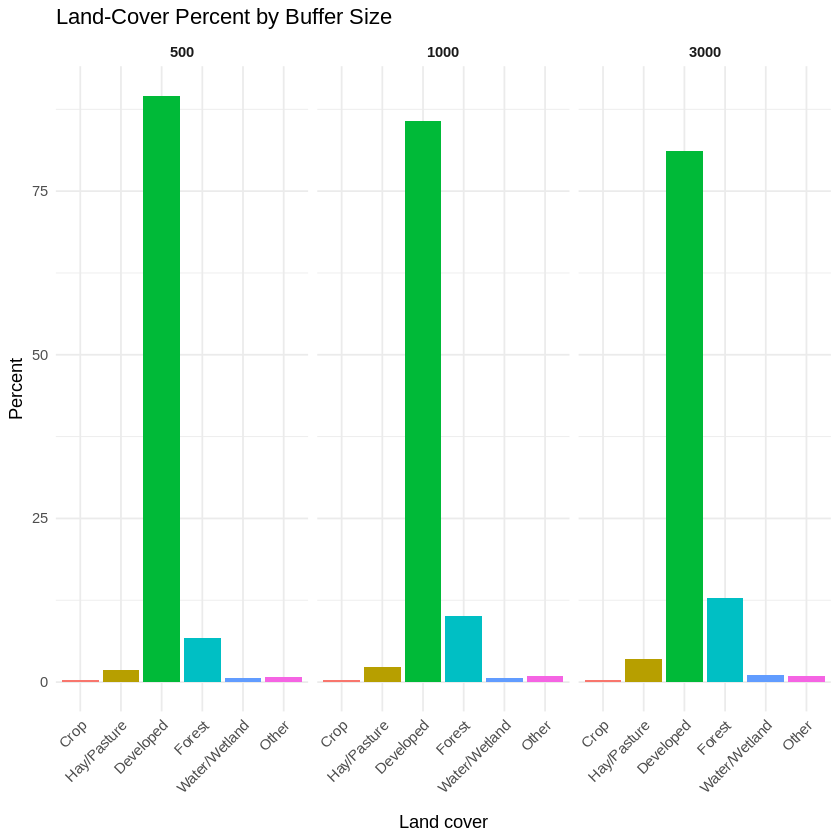

In [15]:
# Load required libraries.
library(dplyr)
library(tidyr)
library(ggplot2)

# Read the CDL buffer features file.
df <- read.csv("/content/amadeus_temp_data/exposure_features/tri_cdl_buffer_features_charlotte_2022.csv",
               stringsAsFactors = FALSE, check.names = FALSE)

# Summarize land-cover percentages by buffer size.
tab <- df %>%
  group_by(buffer_m) %>%
  summarise(
    Crop = mean(pct_crop, na.rm = TRUE),
    `Hay/Pasture` = mean(pct_hay_pasture, na.rm = TRUE),
    Developed = mean(pct_developed, na.rm = TRUE),
    Forest = mean(pct_forest, na.rm = TRUE),
    `Water/Wetland` = mean(pct_water_wetland, na.rm = TRUE),
    Other = mean(pct_other, na.rm = TRUE),
    .groups = "drop"
  )

# Convert the summary table to long format.
plot_df <- tab %>%
  pivot_longer(
    cols = -buffer_m,
    names_to = "land_cover",
    values_to = "percent"
  )

# Order the buffers and land-cover classes.
plot_df$buffer_m <- factor(plot_df$buffer_m, levels = c(500, 1000, 3000))
plot_df$land_cover <- factor(
  plot_df$land_cover,
  levels = c("Crop", "Hay/Pasture", "Developed", "Forest", "Water/Wetland", "Other")
)

# Create the faceted bar chart.
p <- ggplot(plot_df, aes(x = land_cover, y = percent, fill = land_cover)) +
  geom_col() +
  facet_wrap(~ buffer_m, nrow = 1) +
  labs(
    title = "Land-Cover Percent by Buffer Size",
    x = "Land cover",
    y = "Percent"
  ) +
  theme_minimal() +
  theme(
    legend.position = "none",
    strip.text = element_text(face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

# Save a wider version to avoid overlap.
ggsave("land_cover_buffers_wide.png", p, width = 14, height = 4, units = "in", dpi = 300)

# Print the plot.
p

# Mines

In [18]:
# Bulk MRDS Download and Local Filtering

options(timeout = 300, scipen = 999)

library(tidyverse)
library(googledrive)

state <- "NC"
target_county <- "MECKLENBURG"

base_dir <- "/content/amadeus_temp_data"
mines_dir <- file.path(base_dir, "mines")
dir.create(mines_dir, recursive = TRUE, showWarnings = FALSE)

out_state_file  <- file.path(mines_dir, "nc_mines_mrds_all.csv")
out_county_file <- file.path(mines_dir, "mecklenburg_nc_mines_mrds.csv")
metadata_file   <- file.path(mines_dir, "mines_mrds_metadata.csv")
session_file    <- file.path(mines_dir, "sessionInfo_mines_mrds.txt")

# Google Drive folder
drive_folder <- drive_find("Amadeus_Cloud_Downloads", type = "folder")
gdrive_folder <- if (nrow(drive_folder)) {
  as_id(drive_folder$id[1])
} else {
  drive_mkdir("Amadeus_Cloud_Downloads", path = "~")
}

# Download and unzip MRDS
usgs_url <- "https://mrdata.usgs.gov/mrds/mrds-csv.zip"
zip_path <- file.path(mines_dir, "mrds.zip")

download.file(usgs_url, zip_path, mode = "wb", quiet = TRUE)
unzip(zip_path, exdir = mines_dir)

csv_path <- file.path(mines_dir, "mrds.csv")
mines_raw <- read.csv(csv_path, stringsAsFactors = FALSE, check.names = FALSE)

# Normalize column names
names(mines_raw) <- names(mines_raw) |>
  gsub("[^A-Za-z0-9]+", "_", x = _) |>
  tolower() |>
  gsub("^_+|_+$", "", x = _)

names(mines_raw)[names(mines_raw) == "lat"] <- "latitude"
names(mines_raw)[names(mines_raw) == "lon"] <- "longitude"

mines_raw$latitude  <- suppressWarnings(as.numeric(mines_raw$latitude))
mines_raw$longitude <- suppressWarnings(as.numeric(mines_raw$longitude))

# Filter
mines_nc <- mines_raw %>%
  filter(toupper(trimws(state)) == state)

mines_county <- mines_nc %>%
  filter(toupper(trimws(county)) == target_county)

# Coordinate validation
valid_coords <- function(df) {
  with(df, !is.na(latitude) & !is.na(longitude) &
         latitude > 30 & latitude < 40 &
         longitude > -90 & longitude < -70)
}

mines_nc$valid_coordinates <- valid_coords(mines_nc)

if (nrow(mines_county) > 0) {
  mines_county$valid_coordinates <- valid_coords(mines_county)
}

# Write outputs
write.csv(mines_nc, out_state_file, row.names = FALSE)
write.csv(mines_county, out_county_file, row.names = FALSE)

metadata <- data.frame(
  script = "05_mines_nc_mrds_download.R",
  source = "USGS MRDS Bulk",
  url = usgs_url,
  state = state,
  county = target_county,
  rows_nc = nrow(mines_nc),
  rows_county = nrow(mines_county),
  valid_nc = sum(mines_nc$valid_coordinates, na.rm = TRUE),
  run_time = as.character(Sys.time()),
  stringsAsFactors = FALSE
)

write.csv(metadata, metadata_file, row.names = FALSE)
writeLines(capture.output(sessionInfo()), session_file)

cat("Rows NC:", nrow(mines_nc), "\n")
cat("Rows Mecklenburg:", nrow(mines_county), "\n")

# Upload to Drive
files <- c(out_state_file, out_county_file, metadata_file, session_file)

for (f in files) {
  if (file.exists(f)) {
    drive_upload(f, path = gdrive_folder, overwrite = TRUE)
  }
}

Rows NC: 12484 
Rows Mecklenburg: 0 


File trashed:

• nc_mines_mrds_all.csv <id: 1e10JpoHc4d3Lmr_pjPjGSOtUaLr4XjRV>

Local file:

• /content/amadeus_temp_data/mines/nc_mines_mrds_all.csv

Uploaded into Drive file:

• nc_mines_mrds_all.csv <id: 1lF4NXV0nziJoyRuwhUTlFXqtZ1E39rdw>

With MIME type:

• text/csv

File trashed:

• mecklenburg_nc_mines_mrds.csv <id: 1z9laKOQoayHy3_4MqZ-TCmXzEiWukIgY>

Local file:

• /content/amadeus_temp_data/mines/mecklenburg_nc_mines_mrds.csv

Uploaded into Drive file:

• mecklenburg_nc_mines_mrds.csv <id: 1iTFCVUHvtkUmyuaCVrPFUBLoV0r7_51u>

With MIME type:

• text/csv

File trashed:

• mines_mrds_metadata.csv <id: 1OKJcNZc8IdZGMIRKHV6pwEbHWqC8KXWr>

Local file:

• /content/amadeus_temp_data/mines/mines_mrds_metadata.csv

Uploaded into Drive file:

• mines_mrds_metadata.csv <id: 1jK5_AcBTt5a_7IbN-qgbUi-eE7PVcAhx>

With MIME type:

• text/csv

File trashed:

• sessionInfo_mines_mrds.txt <id: 1cYFXu-DCKBU7UxchQtS1FR5cUowtRPLe>

Local file:

• /content/amadeus_temp_data/mines/sessionInfo_mines_mrd

In [21]:
# Bulk MRDS Download and Local Slice

options(timeout = 300, scipen = 999)

library(tidyverse)
library(googledrive)

state <- "NC"
target_county <- "MECKLENBURG"

base_dir <- "/content/amadeus_temp_data"
mines_dir <- file.path(base_dir, "mines")
dir.create(mines_dir, recursive = TRUE, showWarnings = FALSE)

out_state_file  <- file.path(mines_dir, "nc_mines_mrds_all.csv")
out_county_file <- file.path(mines_dir, "mecklenburg_nc_mines_mrds.csv")
metadata_file   <- file.path(mines_dir, "mines_mrds_metadata.csv")


drive_folder_search <- drive_find(pattern = "Amadeus_Cloud_Downloads", type = "folder")
gdrive_folder <- if (nrow(drive_folder_search) > 0) {
  as_id(drive_folder_search$id[1])
} else {
  drive_mkdir("Amadeus_Cloud_Downloads", path = "~")
}

usgs_bulk_url <- "https://mrdata.usgs.gov/mrds/mrds-csv.zip"
zip_path <- file.path(mines_dir, "mrds-csv.zip")

download.file(url = usgs_bulk_url, destfile = zip_path, mode = "wb", quiet = TRUE)
unzip(zip_path, exdir = mines_dir)

extracted_csv <- file.path(mines_dir, "mrds.csv")
mines_raw <- read.csv(extracted_csv, stringsAsFactors = FALSE, check.names = FALSE)

names(mines_raw) <- tolower(gsub("[^A-Za-z0-9]+", "_", names(mines_raw)))
names(mines_raw) <- gsub("_+$|^_+", "", names(mines_raw))

if ("lat" %in% names(mines_raw)) names(mines_raw)[names(mines_raw) == "lat"] <- "latitude"
if ("lon" %in% names(mines_raw)) names(mines_raw)[names(mines_raw) == "lon"] <- "longitude"

if ("latitude" %in% names(mines_raw)) {
  mines_raw$latitude <- suppressWarnings(as.numeric(mines_raw$latitude))
}
if ("longitude" %in% names(mines_raw)) {
  mines_raw$longitude <- suppressWarnings(as.numeric(mines_raw$longitude))
}

if (!"state" %in% names(mines_raw)) stop("Missing required column: state")
if (!"county" %in% names(mines_raw)) stop("Missing required column: county")

mines_nc <- mines_raw %>%
  filter(!is.na(state), toupper(trimws(state)) == state)

mines_county <- mines_nc %>%
  filter(!is.na(county), toupper(trimws(county)) == target_county)

valid_coordinates_fn <- function(df) {
  with(df, !is.na(latitude) & !is.na(longitude) &
         latitude > 30 & latitude < 40 &
         longitude > -90 & longitude < -70)
}

mines_nc$valid_coordinates <- valid_coordinates_fn(mines_nc)
mines_county$valid_coordinates <- valid_coordinates_fn(mines_county)

write.csv(mines_nc, out_state_file, row.names = FALSE)
write.csv(mines_county, out_county_file, row.names = FALSE)

metadata <- data.frame(
  script = "05_mines_nc_mrds_download.R",
  amadeus_installed = requireNamespace("amadeus", quietly = TRUE),
  amadeus_native_mines_supported = FALSE,
  source = "USGS MRDS Bulk National Slice",
  service_url = usgs_bulk_url,
  state = state,
  target_county = target_county,
  rows_nc = nrow(mines_nc),
  rows_target_county = nrow(mines_county),
  valid_coordinate_rows_nc = sum(mines_nc$valid_coordinates, na.rm = TRUE),
  run_time = as.character(Sys.time()),
  stringsAsFactors = FALSE
)

write.csv(metadata, metadata_file, row.names = FALSE)

cat("Rows NC:", nrow(mines_nc), "\n")
cat("Rows Mecklenburg:", nrow(mines_county), "\n")
flush.console()

files_to_upload <- c(out_state_file, out_county_file, metadata_file)

for (target in files_to_upload) {
  if (file.exists(target)) {
    drive_upload(target, path = gdrive_folder, overwrite = TRUE)
  }
}

message("SUCCESS: Mineral Resource data mirrors successfully created on Google Drive.")


MINES DATA DOWNLOAD COMPLETE (BULK FALLBACK)
Rows NC: 12484 
Rows Mecklenburg: 0 


File trashed:

• nc_mines_mrds_all.csv <id: 1lF4NXV0nziJoyRuwhUTlFXqtZ1E39rdw>

Local file:

• /content/amadeus_temp_data/mines/nc_mines_mrds_all.csv

Uploaded into Drive file:

• nc_mines_mrds_all.csv <id: 1Q5T6_KBwfiW1XnkusQmGf4VH3NlBEusn>

With MIME type:

• text/csv

File trashed:

• mecklenburg_nc_mines_mrds.csv <id: 1iTFCVUHvtkUmyuaCVrPFUBLoV0r7_51u>

Local file:

• /content/amadeus_temp_data/mines/mecklenburg_nc_mines_mrds.csv

Uploaded into Drive file:

• mecklenburg_nc_mines_mrds.csv <id: 1TBXVaDuiFXOhXCECwSE8SEFhs9brsUni>

With MIME type:

• text/csv

File trashed:

• mines_mrds_metadata.csv <id: 1jK5_AcBTt5a_7IbN-qgbUi-eE7PVcAhx>

Local file:

• /content/amadeus_temp_data/mines/mines_mrds_metadata.csv

Uploaded into Drive file:

• mines_mrds_metadata.csv <id: 1z38Na084pRuyAddcUqGXxw9xSHVNy7dH>

With MIME type:

• text/csv

File trashed:

• sessionInfo_mines_mrds.txt <id: 19yLDq7r-1cG1RFrLDs0zHiHzI_MEVBI7>

Local file:

• /content/amadeus_temp_data/mines/sessionInfo_mines_mrd

In [22]:
# STEP 06: Validate MRDS Outputs

options(scipen = 999)

library(dplyr)

base_dir <- "/content/amadeus_temp_data/mines"

state_file    <- file.path(base_dir, "nc_mines_mrds_all.csv")
county_file   <- file.path(base_dir, "mecklenburg_nc_mines_mrds.csv")
metadata_file <- file.path(base_dir, "mines_mrds_metadata.csv")

stop_if_missing <- function(path) {
  if (!file.exists(path)) stop(paste("Missing file:", path))
}

stop_if_missing(state_file)
stop_if_missing(county_file)
stop_if_missing(metadata_file)

mines_nc <- read.csv(state_file, stringsAsFactors = FALSE)
mines_ct <- read.csv(county_file, stringsAsFactors = FALSE)
meta <- read.csv(metadata_file, stringsAsFactors = FALSE)

required_nc <- c("state", "county", "latitude", "longitude", "valid_coordinates")
required_ct <- c("state", "county", "latitude", "longitude", "valid_coordinates")

check_cols <- function(df, required, name) {
  missing <- setdiff(required, names(df))
  if (length(missing)) stop(paste(name, "missing columns:", paste(missing, collapse = ", ")))
}

check_cols(mines_nc, required_nc, "state_file")
check_cols(mines_ct, required_ct, "county_file")

valid_coords <- function(df) {
  lat <- suppressWarnings(as.numeric(df$latitude))
  lon <- suppressWarnings(as.numeric(df$longitude))
  !is.na(lat) & !is.na(lon) & lat > 30 & lat < 40 & lon > -90 & lon < -70
}

if (nrow(meta) < 1) stop("Metadata file is empty")

if (!is.na(meta$rows_nc[1]) && meta$rows_nc[1] != nrow(mines_nc)) {
  warning("Row count mismatch for NC")
}

if (!is.na(meta$rows_target_county[1]) && meta$rows_target_county[1] != nrow(mines_ct)) {
  warning("Row count mismatch for county")
}

state_vals <- mines_nc$state[!is.na(mines_nc$state)]
if (length(state_vals) > 0 && !all(toupper(trimws(state_vals)) == "NC")) {
  warning("Non-NC records found in state file")
}

county_vals <- mines_ct$county[!is.na(mines_ct$county)]
if (length(county_vals) > 0 && !all(toupper(trimws(county_vals)) == "MECKLENBURG")) {
  warning("Non-Mecklenburg records found in county file")
}

nc_calc <- valid_coords(mines_nc)
ct_calc <- valid_coords(mines_ct)

if (sum(nc_calc, na.rm = TRUE) != sum(mines_nc$valid_coordinates, na.rm = TRUE)) {
  warning("Mismatch in NC coordinate validation flags")
}

if (sum(ct_calc, na.rm = TRUE) != sum(mines_ct$valid_coordinates, na.rm = TRUE)) {
  warning("Mismatch in county coordinate validation flags")
}

cat("Validation complete\n")
cat("NC rows:", nrow(mines_nc), "\n")
cat("County rows:", nrow(mines_ct), "\n")
cat("Valid NC coordinates:", sum(mines_nc$valid_coordinates, na.rm = TRUE), "\n")
cat("Valid county coordinates:", sum(mines_ct$valid_coordinates, na.rm = TRUE), "\n")

Validation complete
NC rows: 12484 
County rows: 0 
Valid NC coordinates: 0 
Valid county coordinates: 0 


# Hurricane data

In [25]:
library(tidyverse)
library(sf)
library(rvest)

cache_dir <- "/content/amadeus_temp_data/"
if (!dir.exists(cache_dir)) dir.create(cache_dir, recursive = TRUE)

parent_url <- "https://www.nhc.noaa.gov/data/hurdat/"
dest_file <- file.path(cache_dir, "hurdat2_raw.txt")

html_index <- read_html(parent_url)
all_links <- html_index %>% html_nodes("a") %>% html_attr("href")

hurdat_file <- all_links %>%
  keep(~ str_detect(.x, "^hurdat2-1851-\\d{4}-\\d+\\.txt$")) %>%
  sort(decreasing = TRUE) %>%
  first()

if (is.na(hurdat_file)) {
  stop("Failed to resolve HURDAT2 file dynamically from the NHC server matrix.")
}

hurdat_url <- paste0(parent_url, hurdat_file)

if (!file.exists(dest_file)) {
  download.file(hurdat_url, destfile = dest_file, mode = "w")
}

lines <- readLines(dest_file, warn = FALSE) %>%
  str_trim()
lines <- lines[lines != ""]

is_header <- str_detect(lines, "^[A-Z]{2}\\d{6}")
header_indices <- which(is_header)

line_map <- tibble(line_idx = seq_along(lines), is_header = is_header) %>%
  mutate(header_idx = if_else(is_header, line_idx, NA_integer_)) %>%
  fill(header_idx, .direction = "down") %>%
  filter(!is_header)

headers_parsed <- tibble(line_idx = header_indices, text = lines[header_indices]) %>%
  separate(text, into = c("storm_id", "storm_name", "num_rows"), sep = ",", extra = "drop", fill = "right") %>%
  mutate(across(everything(), str_trim))

data_parsed <- tibble(
  line_idx = line_map$line_idx,
  header_idx = line_map$header_idx,
  text = lines[line_map$line_idx]
) %>%
  separate(
    text,
    into = c("date", "time", "record_id", "status", "lat_raw", "lon_raw", "max_wind_kts", "min_press_mb"),
    sep = ",",
    extra = "drop",
    fill = "right"
  ) %>%
  mutate(across(everything(), str_trim))

hurdat_df <- data_parsed %>%
  left_join(headers_parsed, by = c("header_idx" = "line_idx"))

hurdat_clean <- hurdat_df %>%
  filter(str_detect(storm_id, "2022")) %>%
  mutate(
    lat = as.numeric(str_remove(lat_raw, "[NS]")) * if_else(str_detect(lat_raw, "S"), -1, 1),
    lon = as.numeric(str_remove(lon_raw, "[EW]")) * if_else(str_detect(lon_raw, "W"), -1, 1),
    max_wind_kts = as.numeric(max_wind_kts),
    min_press_mb = as.numeric(min_press_mb)
  ) %>%
  filter(!is.na(lat) & !is.na(lon))

if (nrow(hurdat_clean) == 0) {
  stop("Pipeline Halt: No 2022 storm records were extracted. Check raw data mapping.")
}

hurdat_pts_sf <- st_as_sf(hurdat_clean, coords = c("lon", "lat"), crs = 4326)

meck_centroid_sf <- st_sfc(st_point(c(-80.8431, 35.2271)), crs = 4326) %>%
  st_sf() %>%
  st_transform(5070)

hurdat_pts_projected <- st_transform(hurdat_pts_sf, 5070)

distances <- st_distance(hurdat_pts_projected, meck_centroid_sf)
hurdat_pts_projected$distance_to_meck_miles <- as.numeric(distances) / 1609.34

regional_storm_ids <- hurdat_pts_projected %>%
  filter(distance_to_meck_miles <= 100) %>%
  pull(storm_id) %>%
  unique()

if (length(regional_storm_ids) > 0) {
  final_pipeline_tracks_sf <- hurdat_pts_projected %>%
    filter(storm_id %in% regional_storm_ids) %>%
    group_by(storm_id, storm_name) %>%
    summarise(
      min_distance_miles = min(distance_to_meck_miles),
      do_union = FALSE,
      .groups = "drop"
    ) %>%
    st_cast("LINESTRING")

  output_path <- file.path(cache_dir, "hurdat_2022_regional_tracks.gpkg")
  st_write(final_pipeline_tracks_sf, output_path, delete_dsn = TRUE)

  message("Success! Found ", length(regional_storm_ids), " regional storms impacting Mecklenburg footprint.")
  print(final_pipeline_tracks_sf %>% st_drop_geometry() %>% select(storm_id, storm_name, min_distance_miles))
} else {
  message("No 2022 storm tracks passed within a 100-mile radius of Mecklenburg County.")
}


Attaching package: ‘rvest’


The following object is masked from ‘package:readr’:

    guess_encoding




Deleting source `/content/amadeus_temp_data//hurdat_2022_regional_tracks.gpkg' failed
Writing layer `hurdat_2022_regional_tracks' to data source 
  `/content/amadeus_temp_data//hurdat_2022_regional_tracks.gpkg' using driver `GPKG'
Writing 1 features with 3 fields and geometry type Line String.


Success! Found 1 regional storms impacting Mecklenburg footprint.



# A tibble: 1 × 3
  storm_id storm_name min_distance_miles
  <chr>    <chr>                   <dbl>
1 AL092022 IAN                      64.3


In [26]:
gpkg_path <- "/content/amadeus_temp_data/hurdat_2022_regional_tracks.gpkg"
validated_tracks <- sf::st_read(gpkg_path, quiet = TRUE)

print(sf::st_crs(validated_tracks)$epsg) # Should return 5070
print(nrow(validated_tracks))             # Should return 1

[1] 5070
[1] 1


# A tibble: 1 × 2
  storm_name distance_to_charlotte_mi
  <chr>                         <dbl>
1 IAN                            64.3


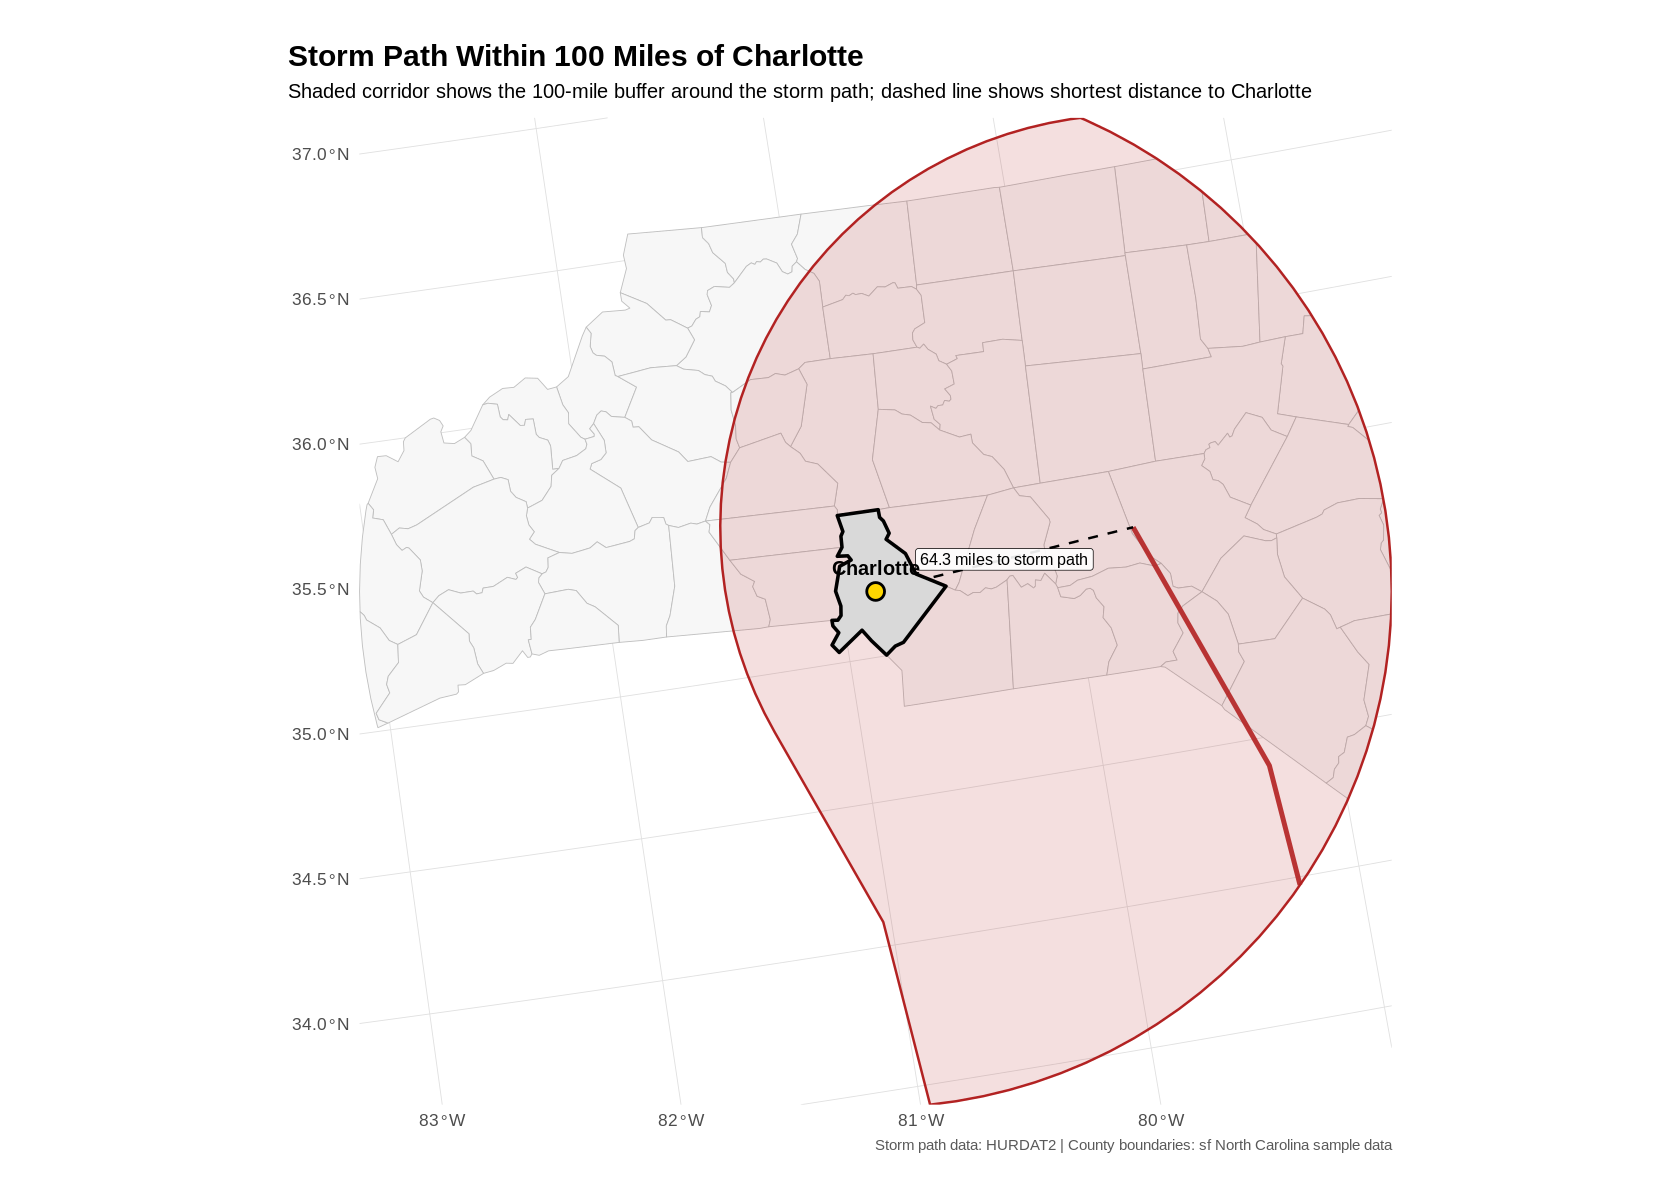

In [56]:
library(tidyverse)
library(sf)
library(ggplot2)

# -----------------------------
# Settings
# -----------------------------

target_crs <- 5070
mile_to_meter <- 1609.344
storm_radius_m <- 100 * mile_to_meter

cache_dir <- "/content/amadeus_temp_data/"
track_file <- file.path(cache_dir, "hurdat_2022_regional_tracks.gpkg")

# -----------------------------
# 1. County boundaries
# -----------------------------

nc <- st_read(system.file("shape/nc.shp", package = "sf"), quiet = TRUE) %>%
  st_transform(target_crs)

meck <- nc %>%
  filter(NAME == "Mecklenburg")

# -----------------------------
# 2. Charlotte point
# -----------------------------

charlotte <- st_as_sf(
  data.frame(name = "Charlotte", lon = -80.8431, lat = 35.2271),
  coords = c("lon", "lat"),
  crs = 4326
) %>%
  st_transform(target_crs)

# -----------------------------
# 3. Storm tracks
# -----------------------------

tracks_sf <- st_read(track_file, quiet = TRUE) %>%
  st_transform(target_crs) %>%
  st_make_valid()

# -----------------------------
# 4. Union storm tracks by storm name
# -----------------------------

tracks_by_storm <- tracks_sf %>%
  group_by(storm_name) %>%
  summarise(.groups = "drop") %>%
  st_make_valid()

# Distance from Charlotte to each storm path
dist_matrix <- st_distance(charlotte, tracks_by_storm)

tracks_by_storm$distance_to_charlotte_mi <- as.numeric(dist_matrix[1, ]) / mile_to_meter

# Keep storms whose path is within 100 miles of Charlotte
touching_tracks <- tracks_by_storm %>%
  filter(distance_to_charlotte_mi <= 100)

print(
  touching_tracks %>%
    st_drop_geometry() %>%
    select(storm_name, distance_to_charlotte_mi)
)

# -----------------------------
# 5. Create 100-mile buffer
# -----------------------------

storm_buffer_100mi <- touching_tracks %>%
  st_buffer(dist = storm_radius_m) %>%
  st_make_valid()

# -----------------------------
# 6. Nearest line from Charlotte to storm path
# -----------------------------

nearest_lines <- lapply(seq_len(nrow(touching_tracks)), function(i) {
  st_nearest_points(
    st_geometry(charlotte),
    st_geometry(touching_tracks[i, ]),
    pairwise = TRUE
  )[[1]]
})

nearest_lines_sf <- st_sf(
  storm_name = touching_tracks$storm_name,
  distance_mi = touching_tracks$distance_to_charlotte_mi,
  geometry = st_sfc(nearest_lines, crs = target_crs)
)

# Midpoint for distance label
nearest_label_points <- st_line_sample(nearest_lines_sf, sample = 0.5) %>%
  st_cast("POINT")

nearest_labels <- st_sf(
  storm_name = nearest_lines_sf$storm_name,
  label = paste0(round(nearest_lines_sf$distance_mi, 1), " miles to storm path"),
  geometry = nearest_label_points
)

# -----------------------------
# 7. Map extent
# -----------------------------

map_extent <- st_buffer(charlotte, dist = storm_radius_m * 1.25)

nc_plot <- suppressWarnings(st_intersection(nc, st_union(map_extent)))
tracks_plot <- suppressWarnings(st_intersection(touching_tracks, st_union(map_extent)))
buffer_plot <- suppressWarnings(st_intersection(storm_buffer_100mi, st_union(map_extent)))
nearest_lines_plot <- suppressWarnings(st_intersection(nearest_lines_sf, st_union(map_extent)))

# -----------------------------
# 8. Plot
# -----------------------------

p <- ggplot() +

  # Regional county background
  geom_sf(
    data = nc_plot,
    fill = "grey97",
    color = "grey75",
    linewidth = 0.25
  ) +

  # 100-mile buffer
  geom_sf(
    data = buffer_plot,
    fill = "firebrick",
    color = "firebrick",
    linewidth = 0.7,
    alpha = 0.14
  ) +

  # Storm path
  geom_sf(
    data = tracks_plot,
    color = "firebrick",
    linewidth = 1.4,
    alpha = 0.9
  ) +

  # Dashed shortest-distance line from Charlotte to storm path
  geom_sf(
    data = nearest_lines_plot,
    color = "black",
    linewidth = 0.7,
    linetype = "dashed"
  ) +

  # Distance label
  geom_sf_label(
    data = nearest_labels,
    aes(label = label),
    size = 3.4,
    label.size = 0.2,
    fill = "white",
    alpha = 0.9
  ) +

  # Mecklenburg highlighted
  geom_sf(
    data = meck,
    fill = "grey85",
    color = "black",
    linewidth = 1.0
  ) +

  # Charlotte point
  geom_sf(
    data = charlotte,
    shape = 21,
    fill = "gold",
    color = "black",
    size = 4.2,
    stroke = 1.2
  ) +

  geom_sf_text(
    data = charlotte,
    aes(label = name),
    nudge_y = 9000,
    size = 4.2,
    fontface = "bold"
  ) +

  labs(
    title = "Storm Path Within 100 Miles of Charlotte",
    subtitle = "Shaded corridor shows the 100-mile buffer around the storm path; dashed line shows shortest distance to Charlotte",
    caption = "Storm path data: HURDAT2 | County boundaries: sf North Carolina sample data",
    x = NULL,
    y = NULL
  ) +

  coord_sf(expand = FALSE) +

  theme_minimal(base_size = 13) +
  theme(
    legend.position = "none",
    panel.grid.major = element_line(color = "grey88", linewidth = 0.25),
    panel.background = element_rect(fill = "white", color = NA),
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(size = 12, margin = margin(b = 10)),
    plot.caption = element_text(size = 9, color = "grey35"),
    plot.title.position = "plot",
    plot.margin = margin(28, 34, 28, 34)
  )

# Make plot larger on screen
options(repr.plot.width = 14, repr.plot.height = 10)
print(p)

# Save high-quality version
ggsave(
  filename = file.path(cache_dir, "charlotte_storm_100mi_buffer_map.png"),
  plot = p,
  width = 10,
  height = 8,
  dpi = 300
)